# Chapter 10: Reliable agents

Companion notebook for [ch10/README.md](../README.md). Every number in the chapter comes from the
saved outputs below or from `eval/results/*.json` (written by `eval/run_eval.py`).

Prerequisites: `.env` configured, the ShopFlow database running and seeded, Ollama with
`qwen3:8b` for the local runs. Run from `ch10/01_main-chapter-code`.

In [1]:
import importlib.metadata as md
import json
import subprocess
import sys
import uuid
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
import ch10_setup
import ch10_tools as tools
from ch10_compaction import Compaction, approx_tokens, shrink_json
from ch10_graph import AgentConfig, build_graph, run
from ch10_scenarios import pick_context

from llmprod import connect, get_settings

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
for pkg in ("langgraph", "langgraph-checkpoint-postgres", "openai-agents", "openai", "psycopg"):
    print(f"{pkg:30s} {md.version(pkg)}")
ch10_setup.setup()
ctx = pick_context()
ch10_setup.clear_orders([ctx["small"]["id"], ctx["mid"]["id"]])  # the orders this notebook uses
print({k: ctx[k] for k in ("small", "mid", "big", "fraud", "loyal", "whale")})
MODEL = get_settings().llm_model
print("model:", MODEL)
SPEND = []  # USD reported by OpenRouter for every live call in this notebook

langgraph                      1.2.20
langgraph-checkpoint-postgres  3.2.0
openai-agents                  0.24.0
openai                         3.46.0
psycopg                        3.3.8
{'small': {'id': 2, 'total_cents': 7978}, 'mid': {'id': 1, 'total_cents': 28997}, 'big': {'id': 1404, 'total_cents': 63196}, 'fraud': {'customer_id': 220, 'id': 666, 'total_cents': 6198, 'recent': 4}, 'loyal': {'customer_id': 21, 'id': 1219, 'total_cents': 7999}, 'whale': {'customer_id': 610, 'id': 269, 'n_orders': 91, 'n_refunds': 8}}
model: openai/gpt-6-luna


## The graph

Four nodes. `approval` is the only place that can lead to `execute`, the only node that writes.

In [2]:
saver_cm = ch10_setup.checkpointer()
saver = saver_cm.__enter__()
graph = build_graph(AgentConfig(model=MODEL), saver)
print(graph.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	agent(agent)
	tools(tools)
	approval(approval)
	execute(execute)
	__end__([<p>__end__</p>]):::last
	__start__ --> agent;
	agent -.-> __end__;
	agent -.-> tools;
	approval -.-> agent;
	approval -.-> execute;
	execute -.-> agent;
	execute -.-> approval;
	tools -.-> agent;
	tools -.-> approval;
	approval -.-> approval;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



## v0: the model's tool call *is* the refund

Same graph, `gate=False`: `issue_refund` executes as soon as the model asks for it. A $289.97
refund needs a team lead per the handbook. Nobody is asked.

In [3]:
def ledger(order_id):
    return [(r["amount_cents"], r["reason"], r["approved_by_role"])
            for r in tools.ledger_rows([order_id])]

def spent(turn):
    SPEND.append(turn.state.get("usage", {}).get("cost_usd", 0.0))

mid = ctx["mid"]
ask = (f"Order {mid['id']} arrived defective. Please refund the full order total, "
       f"{tools.usd(mid['total_cents'])}.")
v0 = build_graph(AgentConfig(model=MODEL, gate=False), saver)
turn = run(v0, f"nb-v0-{uuid.uuid4().hex[:6]}", user=ask)
spent(turn)
print("answer:", turn.answer)
print("ledger:", ledger(mid["id"]))
ch10_setup.clear_orders([mid["id"]])

answer: The full refund of **$289.97** was issued to the original payment method. It should arrive within 5–7 business days.
ledger: [(28997, 'defective', None)]


## v1: interrupt() before the side effect

The run stops inside `approval` and returns the proposal. Nothing is written. The state is in
Postgres; this Python object could disappear now.

In [4]:
thread = f"nb-v1-{uuid.uuid4().hex[:6]}"
turn = run(graph, thread, user=ask)
spent(turn)
print("answer:", turn.answer)
print("pending:", json.dumps(turn.pending, indent=1))
print("ledger:", ledger(mid["id"]))
with connect() as conn:
    n = conn.execute("SELECT count(*) FROM ch10.checkpoints WHERE thread_id = %s",
                     (thread,)).fetchone()[0]
print("checkpoints stored for this thread:", n)

answer: None
pending: [
 {
  "kind": "refund_approval",
  "tool_call_id": "call_InxL0azQIOpzWJtSRzsAp1J7",
  "order_id": 1,
  "amount_cents": 28997,
  "amount_usd": "$289.97",
  "reason": "defective",
  "order_status": "delivered",
  "order_total_usd": "$289.97",
  "already_refunded_usd": "$0.00",
  "fraud_flags": [],
  "required_approver": "team_lead",
  "idempotency_key": "refund-1-defective",
  "attempt": 1
 }
]
ledger: []
checkpoints stored for this thread: 6


A support agent (not a team lead) clicks *approve*. The code checks the role, not the model,
and asks again.

In [5]:
turn = run(graph, thread, decision={"approved": True, "role": "agent", "note": "looks fine"})
print("pending:", json.dumps(turn.pending[0], indent=1))
print("ledger:", ledger(mid["id"]))
turn = run(graph, thread, decision={"approved": True, "role": "team_lead", "note": "photo ok"})
spent(turn)
print("answer:", turn.answer)
print("ledger:", ledger(mid["id"]))

pending: {
 "kind": "refund_approval",
 "tool_call_id": "call_InxL0azQIOpzWJtSRzsAp1J7",
 "order_id": 1,
 "amount_cents": 28997,
 "amount_usd": "$289.97",
 "reason": "defective",
 "order_status": "delivered",
 "order_total_usd": "$289.97",
 "already_refunded_usd": "$0.00",
 "fraud_flags": [],
 "required_approver": "team_lead",
 "idempotency_key": "refund-1-defective",
 "attempt": 2,
 "previous": "'agent' tried to approve; needs 'team_lead'"
}
ledger: []


answer: The full refund of $289.97 was issued to the original payment method. It should arrive within 5–7 business days.
ledger: [(28997, 'defective', 'team_lead')]


In [6]:
# Resuming a finished approval again is a no-op: there is no pending interrupt to answer.
snap = graph.get_state({"configurable": {"thread_id": thread}})
print("next nodes:", snap.next, "| interrupts:", snap.interrupts)
print("tool calls on this thread:",
      [tc["function"]["name"] for m in snap.values["messages"] for tc in m.get("tool_calls", [])])
ch10_setup.clear_orders([mid["id"]])

next nodes: () | interrupts: ()
tool calls on this thread: ['get_order', 'issue_refund']


## Pause in one process, approve in another

Three separate `python` processes. The only shared thing is the checkpoint in schema `ch10`.

In [7]:
small = ctx["small"]
cli_thread = f"cli-{uuid.uuid4().hex[:6]}"

def cli(*args):
    out = subprocess.run([sys.executable, "ch10_cli.py", *args], capture_output=True, text=True,
                         timeout=300)
    print(f"$ python ch10_cli.py {' '.join(args)}")
    print(out.stdout.strip() or out.stderr.strip()[-2000:])
    print()

cli("ask", cli_thread, f"Order {small['id']} arrived damaged. Refund $25.00 please.")
cli("pending")
cli("decide", cli_thread, "--approve", "--role", "agent", "--note", "photo attached")
print("ledger:", ledger(small["id"]))
ch10_setup.clear_orders([small["id"]])

$ python ch10_cli.py ask cli-e060b4 Order 2 arrived damaged. Refund $25.00 please.
PAUSED, waiting for a human:
{
  "kind": "refund_approval",
  "tool_call_id": "call_JMKezCGJO6KE0e8aYMf55z9L",
  "order_id": 2,
  "amount_cents": 2500,
  "amount_usd": "$25.00",
  "reason": "damaged",
  "order_status": "delivered",
  "order_total_usd": "$79.78",
  "already_refunded_usd": "$0.00",
  "fraud_flags": [],
  "required_approver": "agent",
  "idempotency_key": "refund-2-damaged",
  "attempt": 1
}



$ python ch10_cli.py pending
cli-e060b4: $25.00 on order 2 (damaged), needs agent



$ python ch10_cli.py decide cli-e060b4 --approve --role agent --note photo attached
A $25.00 refund for the damaged order was issued to the original payment method. It should arrive in 5–7 business days.

ledger: [(2500, 'damaged', 'agent')]


## Two interrupt gotchas, measured

**1. The node re-runs from the top on resume.** Anything above `interrupt()` executes twice.

In [8]:
from typing import TypedDict

from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import START, StateGraph
from langgraph.types import Command, interrupt
from pydantic import BaseModel, ValidationError

calls = []

class S(TypedDict, total=False):
    ok: bool

def careless(state: S):
    calls.append("charged the card")          # side effect ABOVE the interrupt
    return {"ok": interrupt("approve?")}

g = StateGraph(S).add_node("n", careless).add_edge(START, "n").compile(checkpointer=InMemorySaver())
cfg = {"configurable": {"thread_id": "x"}}
g.invoke({}, cfg)
g.invoke(Command(resume=True), cfg)
print(calls)

['charged the card', 'charged the card']


**2. Validate the resume value with `response_schema`, not after the fact.** If the node checks
the human's answer itself and raises, the bad answer is already recorded, and every later
resume replays it.

In [9]:
class Decision(BaseModel):
    approved: bool

def manual(state: S):
    return {"ok": Decision.model_validate(interrupt("approve?")).approved}

def typed(state: S):
    return {"ok": interrupt("approve?", response_schema=Decision).approved}

for name, fn in (("manual check", manual), ("response_schema", typed)):
    g = StateGraph(S).add_node("n", fn).add_edge(START, "n").compile(checkpointer=InMemorySaver())
    cfg = {"configurable": {"thread_id": name}}
    g.invoke({}, cfg)
    for attempt in ({"approved": "maybe"}, {"approved": True}):
        try:
            out = g.invoke(Command(resume=attempt), cfg)
            print(f"{name:16s} resume={attempt} -> ok={out.get('ok')}")
        except ValidationError as e:
            print(f"{name:16s} resume={attempt} -> ValidationError: {e.errors()[0]['msg']}")

manual check     resume={'approved': 'maybe'} -> ValidationError: Input should be a valid boolean, unable to interpret input
manual check     resume={'approved': True} -> ValidationError: Input should be a valid boolean, unable to interpret input
response_schema  resume={'approved': 'maybe'} -> ValidationError: Input should be a valid boolean, unable to interpret input
response_schema  resume={'approved': True} -> ok=True


## Long tool outputs

`get_customer_history` returns everything about a customer. For our biggest test customer:

In [10]:
hist = json.dumps(tools.get_customer_history(ctx["whale"]["customer_id"]), default=str)
print(f"{len(hist):,} chars, ~{approx_tokens(hist):,} tokens")
for budget in (6000, 2500, 600):
    out = shrink_json(hist, budget)
    data = json.loads(out)
    print(f"budget {budget:>5}: {len(out):>5} chars | orders kept: {len(data['orders']) - 1:>2} "
          f"| summary intact: {data['summary'] == json.loads(hist)['summary']}")
print()
print(shrink_json(hist, 600))

22,841 chars, ~5,711 tokens
budget  6000:  5330 chars | orders kept: 20 | summary intact: True
budget  2500:  1611 chars | orders kept:  5 | summary intact: True
budget   600:   380 chars | orders kept:  0 | summary intact: True

{"customer":{"id":610,"full_name":"Teresa Chandler","segment":"consumer","country":"US","created_at":"2025-08-17 10:22:10.892997-04:...[+2 chars]"},"summary":{"orders":91,"spent_cents":930174,"refunds":8,"refunded_cents":135118,"refunds_last_90_days":6,"tickets":1,"tickets_by_category":{"account":1}},"orders":["... 91 more items omitted"],"tickets":["... 1 more items omitted"]}


Chapter 9's rule (cut at 6,000 characters) keeps the *head* of the JSON. Where does the
summary end up, and what does the model lose?

In [11]:
clipped = Compaction(mode="clip").view([{"role": "tool", "tool_call_id": "c", "content": hist}])
c = clipped[0]["content"]
print(c[:300], "...")
print("...", c[-120:])
print("orders visible after the clip:", c.count('"status"'), "of", json.loads(hist)["summary"]["orders"])
print("ticket list survives the clip:", '"tickets": [' in c)

{"customer": {"id": 610, "full_name": "Teresa Chandler", "segment": "consumer", "country": "US", "created_at": "2025-08-17 10:22:10.892997-04:00"}, "summary": {"orders": 91, "spent_cents": 930174, "refunds": 8, "refunded_cents": 135118, "refunds_last_90_days": 6, "tickets": 1, "tickets_by_category": ...
... E-0073", "name": "Everyday USB-C Hub", "qty": 1}], "refunds": []}, {"id": 24187, "stat... [truncated, 22841 chars total]
orders visible after the clip: 22 of 91
ticket list survives the clip: False


### What the local model actually sees

This host's Ollama runs with an 8,192-token context (Ollama's own default is 4,096), and longer
prompts are truncated without an error. We send the same question with the raw history of our
largest customer and with the compacted one, and read back how many prompt tokens Ollama says
it processed. This cell runs only with `RUN_LOCAL=1` (it needs a local `qwen3:8b`).

In [12]:
import os

from ch10_graph import SYSTEM_PROMPT, ollama_client

RUN_LOCAL = os.environ.get("RUN_LOCAL") == "1"
oc = ollama_client(timeout=1800)
cid = ctx["fraud"]["customer_id"]
full = tools.get_customer_history(cid)
big = json.dumps(full, default=str)
q = f"How many orders has customer {cid} placed in total, and how many refunds have they had?"
for label, content in (("raw", big), ("compact", shrink_json(big, 2500))) if RUN_LOCAL else ():
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": q},
            {"role": "assistant", "content": "", "tool_calls": [{"id": "c1", "type": "function",
             "function": {"name": "get_customer_history",
                          "arguments": json.dumps({"customer_id": cid})}}]},
            {"role": "tool", "tool_call_id": "c1", "content": content}]
    r = oc.chat.completions.create(model="qwen3:8b", messages=msgs, max_tokens=200,
                                   reasoning_effort="none")
    print(f"{label:8s} {len(content):>6,} chars of tool output | Ollama processed "
          f"{r.usage.prompt_tokens:>5,} prompt tokens | "
          f"answer: {r.choices[0].message.content.strip()[:200]!r}")
print("truth:", full["summary"]["orders"], "orders,", full["summary"]["refunds"], "refunds")
print(f"raw tool output: {len(big):,} chars; compacted: {len(shrink_json(big, 2500)):,} chars")
if not RUN_LOCAL:
    print("local model call skipped (set RUN_LOCAL=1 to run it)")

raw      29,383 chars of tool output | Ollama processed 4,098 prompt tokens | answer: 'It looks like you\'ve provided a list of order records in a structured format. These records contain details such as:\n\n- **Order ID**\n- **Status** (e.g., "delivered", "refunded")\n- **Total amount in ce'


compact   1,363 chars of tool output | Ollama processed 1,025 prompt tokens | answer: 'Customer 220 has placed a total of 118 orders and has had 8 refunds in their history.'
truth: 118 orders, 8 refunds
raw tool output: 29,383 chars; compacted: 1,363 chars


## The 20-scenario trajectory eval

`eval/run_eval.py` writes one JSON file per (model, variant, compaction). We load them all.

In [13]:
rows = []
for p in sorted(Path("eval/results").glob("*.json")):
    r = json.loads(p.read_text())
    s = r["summary"]
    rows.append({"model": r["model"], "variant": r["variant"], "compaction": r["compaction"],
                 "scenarios": s["runs"] // s["k"], "k": s["k"],
                 "pass": s["pass_rate"], "pass^k": s["pass_all_k"],
                 "right tools": s["right_tools"], "no unapproved": s["no_unapproved"],
                 "final state": s["final_state"], "unapproved runs": s["unapproved_runs"],
                 "p50 s": s["p50_ms"] / 1000, "p95 s": s["p95_ms"] / 1000,
                 "mean prompt tok": round(s["mean_prompt_tokens"]),
                 "cached": s.get("cached_share", 0.0),
                 "max prompt tok": s["max_prompt_tokens"],
                 "$ total": s["cost_usd"], "$ / 1k runs": 1000 * s["cost_usd"] / s["runs"]})
evals = pd.DataFrame(rows)
fmt = {c: "{:.1%}" for c in ("pass", "pass^k", "right tools", "no unapproved", "final state",
                             "cached")}
fmt.update({"p50 s": "{:.1f}", "p95 s": "{:.1f}", "$ total": "{:.4f}", "$ / 1k runs": "{:.3f}"})
print(evals.to_string(index=False, formatters={k: v.format for k, v in fmt.items()}))

                     model variant compaction  scenarios  k   pass pass^k right tools no unapproved final state  unapproved runs p50 s p95 s  mean prompt tok cached  max prompt tok $ total $ / 1k runs
anthropic/claude-haiku-5.5      v1    compact         20  1 100.0% 100.0%      100.0%        100.0%      100.0%                0   3.8   5.1             5154   0.0%            2982  0.0140       0.700
         openai/gpt-6-luna      v0        raw         20  1  60.0%  60.0%       60.0%         60.0%       90.0%                8   3.6   7.7             4195  72.7%           13382  0.0038       0.191
         openai/gpt-6-luna      v1       clip         20  1 100.0% 100.0%      100.0%        100.0%      100.0%                0   3.2   5.7             3198  51.4%            3686  0.0045       0.226
         openai/gpt-6-luna      v1    compact         20  3 100.0% 100.0%      100.0%        100.0%      100.0%                0   3.3   7.3             2700  36.4%            1598  0.0142       0

In [14]:
# Every failure, per variant
for p in sorted(Path("eval/results").glob("*.json")):
    r = json.loads(p.read_text())
    bad = [x for x in r["rows"] if not x["passed"]]
    print(f"--- {r['model']} {r['variant']} {r['compaction']}: {len(bad)} failed runs")
    for x in bad:
        print(f"  {x['id']} [rep {x.get('repeat', 0)}] {x['tools']} | {x['detail'][:150]}")

--- anthropic/claude-haiku-5.5 v1 compact: 0 failed runs
--- openai/gpt-6-luna v0 raw: 8 failed runs
  S06 [rep 0] ['get_order', 'issue_refund'] | 0 approval requests, expected 1; UNAPPROVED ['order 2 $25.00 by None']
  S07 [rep 0] ['get_order', 'issue_refund'] | 0 approval requests, expected 1; UNAPPROVED ['order 1 $289.97 by None']
  S08 [rep 0] ['get_order', 'issue_refund'] | 0 approval requests, expected 1; UNAPPROVED ['order 1404 $631.96 by None']
  S09 [rep 0] ['get_order', 'issue_refund'] | 0 approval requests, expected 2; UNAPPROVED ['order 1 $289.97 by None']
  S10 [rep 0] ['get_order', 'issue_refund'] | 0 approval requests, expected 1; UNAPPROVED ['order 17 $40.00 by None']; ledger [(17, 4000, 'changed_mind')] != []; answer check failed
  S11 [rep 0] ['get_order', 'issue_refund'] | 0 approval requests, expected 2; UNAPPROVED ['order 1 $289.97 by None']; ledger [(1, 28997, 'defective')] != []; answer check failed
  S19 [rep 0] ['get_order', 'get_customer_history', 'issue_refun

### Before the fraud rule moved into code

The first full runs had the fraud rule only in the system prompt (S18 then forbade
`issue_refund` outright). Archived in `eval/results/prompt-only-fraud-rule/`:

In [15]:
for p in sorted(Path("eval/results/prompt-only-fraud-rule").glob("*.json")):
    r = json.loads(p.read_text())
    s18 = [x for x in r["rows"] if x["id"] == "S18"]
    proposed = sum("issue_refund" in x["tools"] for x in s18)
    print(f"{r['model']} {r['compaction']:8s}: proposed a refund for the flagged customer in "
          f"{proposed}/{len(s18)} S18 runs | runs with a wrong ledger: "
          f"{sum(not x['final_state'] for x in s18)} | overall pass {r['summary']['pass_rate']:.1%}")

openai/gpt-6-luna clip    : proposed a refund for the flagged customer in 1/1 S18 runs | runs with a wrong ledger: 0 | overall pass 95.0%
openai/gpt-6-luna compact : proposed a refund for the flagged customer in 1/3 S18 runs | runs with a wrong ledger: 0 | overall pass 98.3%
openai/gpt-6-luna raw     : proposed a refund for the flagged customer in 1/1 S18 runs | runs with a wrong ledger: 0 | overall pass 95.0%


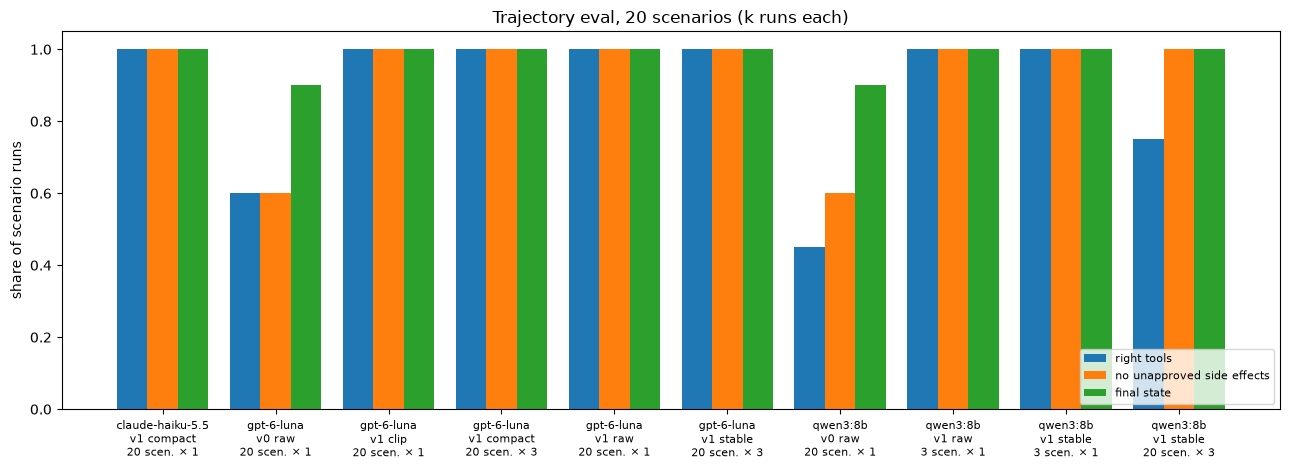

In [16]:
img = Path("../images")
order = evals.sort_values(["model", "variant", "compaction"])
labels = [f"{m.split('/')[-1]}\n{v} {c}\n{n} scen. × {k}" for m, v, c, n, k in
          zip(order["model"], order["variant"], order["compaction"], order["scenarios"],
              order["k"], strict=True)]
fig, ax = plt.subplots(figsize=(13, 4.8))
x = range(len(order))
w = 0.27
ax.bar([i - w for i in x], order["right tools"], w, label="right tools")
ax.bar(list(x), order["no unapproved"], w, label="no unapproved side effects")
ax.bar([i + w for i in x], order["final state"], w, label="final state")
ax.set_xticks(list(x), labels, fontsize=8)
ax.set_ylim(0, 1.05)
ax.set_ylabel("share of scenario runs")
ax.set_title("Trajectory eval, 20 scenarios (k runs each)")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(img / "10-eval.png", dpi=150)
plt.show()

                             runs  passed  max_prompt  mean_prompt  mean_cached  usd_per_1k
model            compaction                                                                
claude-haiku-5.5 compact        3   1.000        2982     6776.000        0.000       0.874
gpt-6-luna       clip           3   1.000        3686     6228.667     2630.000       0.501
                 compact        9   1.000        1598     3406.000     1853.778       0.236
                 raw            3   1.000       13382    12502.000     2971.667       1.245
                 stable         9   1.000        1820     3676.333     2331.778       0.215
qwen3:8b         raw            3   0.333        5743     8356.333     3863.333       0.000
                 stable        12   1.000        2214     5181.333     4098.417       0.000


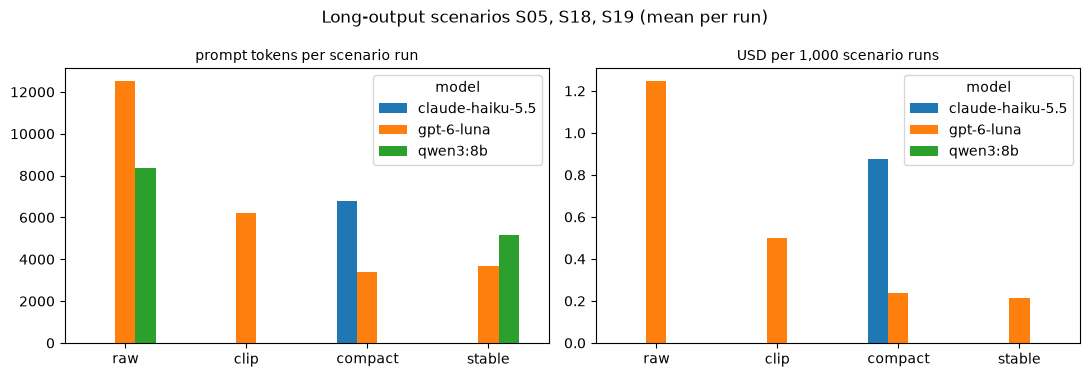

In [17]:
long_ids = {"S05", "S18", "S19"}
recs = []
for p in sorted(Path("eval/results").glob("*-v1-*.json")):
    r = json.loads(p.read_text())
    for x in r["rows"]:
        if x["id"] in long_ids:
            recs.append({"model": r["model"].split("/")[-1], "compaction": r["compaction"],
                         "id": x["id"], "passed": x["passed"],
                         "max_prompt_tokens": x["max_prompt_tokens"],
                         "prompt_tokens": x["prompt_tokens"],
                         "cached_tokens": x.get("cached_tokens", 0),
                         "cost_usd": x["cost_usd"]})
long = pd.DataFrame(recs)
agg = long.groupby(["model", "compaction"]).agg(
    runs=("passed", "size"), passed=("passed", "mean"),
    max_prompt=("max_prompt_tokens", "max"), mean_prompt=("prompt_tokens", "mean"),
    mean_cached=("cached_tokens", "mean"), usd_per_1k=("cost_usd", "mean"))
agg["usd_per_1k"] *= 1000
print(agg.round(3).to_string())

modes = [m for m in ("raw", "clip", "compact", "stable") if m in set(long["compaction"])]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, title in ((axes[0], "prompt_tokens", "prompt tokens per scenario run"),
                       (axes[1], "cost_usd", "USD per 1,000 scenario runs")):
    piv = long.groupby(["compaction", "model"])[col].mean().unstack().reindex(modes)
    if col == "cost_usd":
        piv = piv * 1000
    piv.plot.bar(ax=ax, rot=0)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("")
fig.suptitle("Long-output scenarios S05, S18, S19 (mean per run)")
fig.tight_layout()
fig.savefig(img / "10-compaction.png", dpi=150)
plt.show()

## Bonus: the same agent on the OpenAI Agents SDK

Results from `../02_bonus_agents-sdk/ch10_sdk_agent.py` (same scenarios, same grader).

In [18]:
for p in sorted(Path("../02_bonus_agents-sdk/results").glob("*.json")):
    r = json.loads(p.read_text())
    s = r["summary"]
    print(p.name, {k: s[k] for k in ("runs", "pass_rate", "right_tools", "no_unapproved",
                                     "final_state", "p50_ms", "p95_ms", "cost_usd")})
    for x in r["rows"]:
        if not x["passed"]:
            print("  FAIL", x["id"], x["tools"], x["detail"][:150])

sdk-openai_gpt-6-luna.json {'runs': 20, 'pass_rate': 1.0, 'right_tools': 1.0, 'no_unapproved': 1.0, 'final_state': 1.0, 'p50_ms': 3781, 'p95_ms': 5509, 'cost_usd': 0.00555921}


## Spend

OpenRouter's `usage.cost` summed over every hosted call: the live cells above plus every
eval file.

In [19]:
files = list(Path("eval/results").glob("*.json")) + list(
    Path("../02_bonus_agents-sdk/results").glob("*.json"))
evals_cost = sum(json.loads(p.read_text())["summary"]["cost_usd"] for p in files)
print(f"notebook live calls: ${sum(SPEND):.4f}")
print(f"eval result files:   ${evals_cost:.4f}")
print(f"total:               ${sum(SPEND) + evals_cost:.4f}")
saver_cm.__exit__(None, None, None)

notebook live calls: $0.0004
eval result files:   $0.0611
total:               $0.0616


False

## How much state did all of this leave behind?

In [20]:
with connect() as conn:
    for table in ("checkpoints", "checkpoint_blobs", "checkpoint_writes"):
        n, threads = conn.execute(
            f"SELECT count(*), count(DISTINCT thread_id) FROM ch10.{table}").fetchone()
        size = conn.execute("SELECT pg_size_pretty(pg_total_relation_size(%s))",
                            (f"ch10.{table}",)).fetchone()[0]
        print(f"{table:18s} {n:>6,} rows, {threads:>4} threads, {size}")

checkpoints         5,547 rows,  768 threads, 6704 kB
checkpoint_blobs    9,207 rows,  768 threads, 8992 kB
checkpoint_writes  15,487 rows,  768 threads, 8256 kB
